# Satellite Dataset: Preprocessing, Export, and Exploratory Visualization

**Purpose:** document the original AUMtree preprocessing, verify the loaded Satellite dataset, visualize its structure, and export the final model-ready CSV.

This notebook uses the original repository's `src.data.load_dataset()` function so the preprocessing is reproducible and consistent with the base project.

## 1. Imports and project path

Run this notebook from the repository. The path-detection cell also supports opening it from the `notebooks/` folder in VS Code.

In [3]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Find the repository root (the folder containing src/data.py).
current = Path.cwd()
candidates = [current, *current.parents]
PROJECT_ROOT = next(
    (path for path in candidates if (path / "src" / "data.py").exists()),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not find the repository root. Open this notebook from inside the AUMtree repository."
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)


Project root: d:\Research Paper\Git\Soft-Reweighting-Samples


## 2. Load the Satellite Dataset

We download the official **Statlog (Landsat Satellite)** dataset directly from the UCI Machine Learning Repository.

The dataset is provided in two files:
- `sat.trn` — the original training data.
- `sat.tst` — the original testing data.

We combine both files to work with the complete dataset, following the same approach used in the original AUMtree repository.

Each row contains 36 numerical features and one class label. No feature scaling, imputation, or other feature transformations are applied at this stage.

In [4]:
import requests
from io import StringIO

UCI_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/satimage/"

train_response = requests.get(UCI_URL + "sat.trn")
test_response = requests.get(UCI_URL + "sat.tst")

train_response.raise_for_status()
test_response.raise_for_status()

train_data = pd.read_csv(
    StringIO(train_response.text), sep=r"\s+", header=None
)

test_data = pd.read_csv(
    StringIO(test_response.text), sep=r"\s+", header=None
)

raw_data = pd.concat([train_data, test_data], ignore_index=True)

print("Dataset downloaded successfully!")
print("Shape:", raw_data.shape)

Dataset downloaded successfully!
Shape: (6435, 37)


In [5]:
# Check the downloaded dataset structure

print("Combined dataset shape:", raw_data.shape)

print("\nFirst five rows:")
display(raw_data.head())

print("\nDataset information:")
raw_data.info()

Combined dataset shape: (6435, 37)

First five rows:


,0,1,2,3,4,5,6,7,8,9,...,27,28,29,30,31,32,33,34,35,36
0,92,115,120,94,84,102,106,79,84,102,...,104,88,121,128,100,84,107,113,87,3
1,84,102,106,79,84,102,102,83,80,102,...,100,84,107,113,87,84,99,104,79,3
2,84,102,102,83,80,102,102,79,84,94,...,87,84,99,104,79,84,99,104,79,3
3,80,102,102,79,84,94,102,79,80,94,...,79,84,99,104,79,84,103,104,79,3
4,84,94,102,79,80,94,98,76,80,102,...,79,84,103,104,79,79,107,109,87,3



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 37 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   0       6435 non-null   int64
 1   1       6435 non-null   int64
 2   2       6435 non-null   int64
 3   3       6435 non-null   int64
 4   4       6435 non-null   int64
 5   5       6435 non-null   int64
 6   6       6435 non-null   int64
 7   7       6435 non-null   int64
 8   8       6435 non-null   int64
 9   9       6435 non-null   int64
 10  10      6435 non-null   int64
 11  11      6435 non-null   int64
 12  12      6435 non-null   int64
 13  13      6435 non-null   int64
 14  14      6435 non-null   int64
 15  15      6435 non-null   int64
 16  16      6435 non-null   int64
 17  17      6435 non-null   int64
 18  18      6435 non-null   int64
 19  19      6435 non-null   int64
 20  20      6435 non-null   int64
 21  21      6435 non-null   int64
 22  22      6435 non-null   int64
 23  23

## 3. What preprocessing has already been applied?

| Operation | What the original loader does |
|---|---|
| Read source files | Reads `sat.trn` and `sat.tst` from the UCI archive |
| Combine files | Concatenates the two official files into one dataset |
| Feature names | Assigns 36 names: `band_0` … `band_35` |
| Target name | Names the target column `label` |
| Target encoding | Converts the six original class labels to integers `0` … `5` |
| Feature scaling | Not applied |
| Feature encoding | Not needed: the 36 spectral features are already numeric |
| Missing-value imputation | Not applied by the loader |
| Feature removal | Not applied by the loader |
| Train/validation/test split | Not performed by the loader |

The following cells independently verify the data quality rather than assuming the loader has cleaned everything.

## 4. Data quality checks

In [6]:
# Prepare the dataset for quality checks

feature_columns = [f"band_{i}" for i in range(36)]

raw_data.columns = feature_columns + ["original_label"]

# Encode class labels as integers from 0 to 5
class_mapping = {
    label: index
    for index, label in enumerate(sorted(raw_data["original_label"].unique()))
}

raw_data["label"] = raw_data["original_label"].map(class_mapping)

# Final dataset
df = raw_data[feature_columns + ["label"]]

features = df.drop(columns="label")
target = df["label"]

print("Rows:", len(df))
print("Feature count:", features.shape[1])
print("Target classes:", sorted(target.unique().tolist()))
print("Missing feature values:", int(features.isna().sum().sum()))
print("Infinite feature values:", int(np.isinf(features.to_numpy()).sum()))
print("Duplicate feature rows:", int(features.duplicated().sum()))
print("Constant features:", features.columns[features.nunique() <= 1].tolist())
print("Feature data types:")
display(features.dtypes.value_counts())
print("Feature value range:", int(features.min().min()), "to", int(features.max().max()))

Rows: 6435
Feature count: 36
Target classes: [0, 1, 2, 3, 4, 5]
Missing feature values: 0
Infinite feature values: 0
Duplicate feature rows: 0
Constant features: []
Feature data types:


int64    36
Name: count, dtype: int64

Feature value range: 27 to 157


In [7]:
# Class counts and percentages
class_summary = pd.DataFrame({
    "count": target.value_counts().sort_index(),
    "percentage": target.value_counts(normalize=True).sort_index() * 100
})
display(class_summary.round(2))


,count,percentage
label,,
0,1533,23.82
1,703,10.92
2,1358,21.10
3,626,9.73
4,707,10.99
5,1508,23.43


## 5. Visualizations

These plots describe the dataset before any poisoning or defense method is applied.

### 5.1 Target class distribution

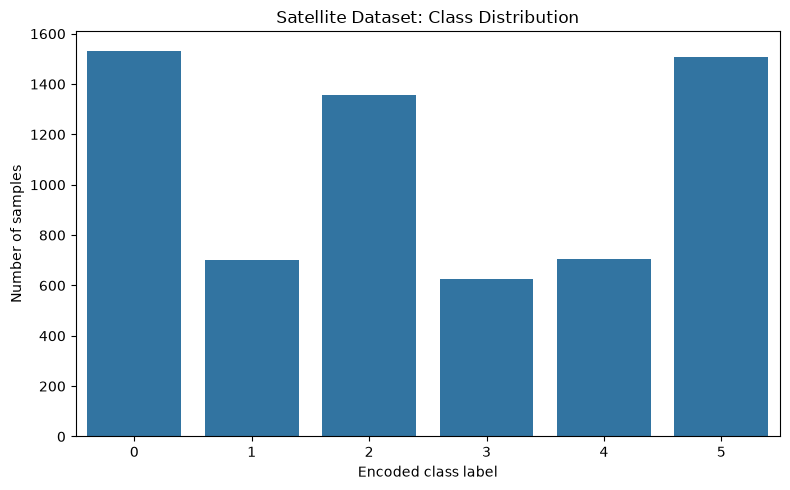

In [8]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="label", order=sorted(target.unique()))
ax.set_title("Satellite Dataset: Class Distribution")
ax.set_xlabel("Encoded class label")
ax.set_ylabel("Number of samples")
plt.tight_layout()
plt.show()


### 5.2 Distribution of spectral features

The first six bands are shown individually for a readable overview. The full set of 36 features is retained.

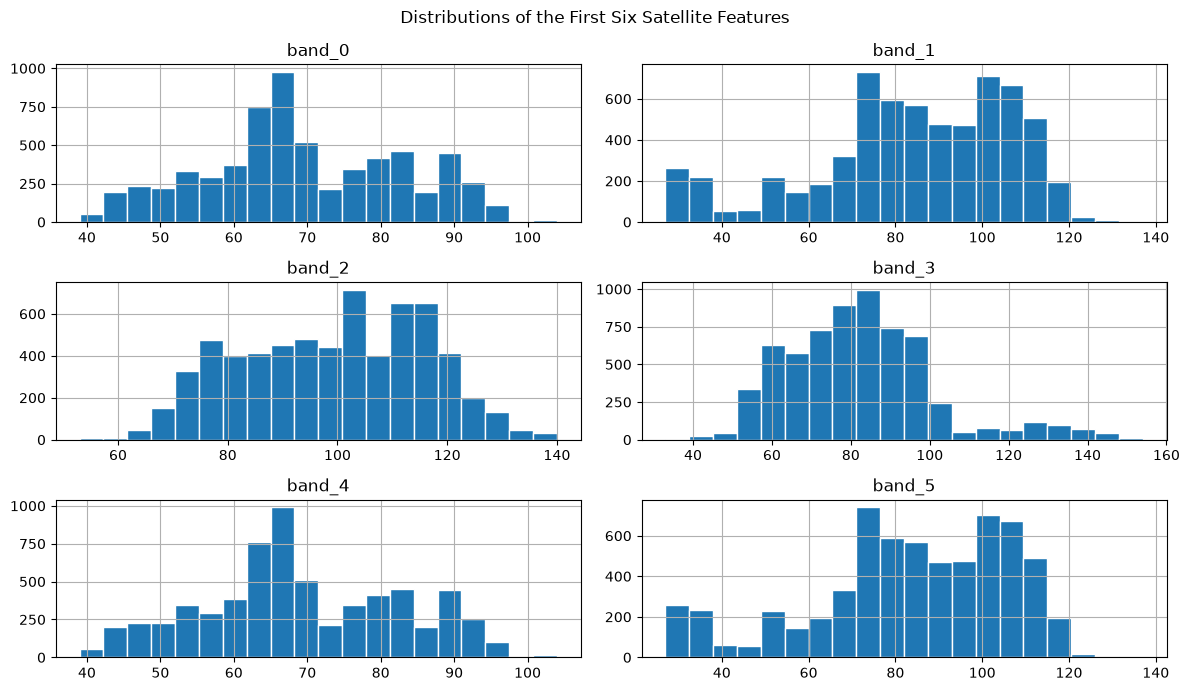

In [9]:
features.iloc[:, :6].hist(figsize=(12, 7), bins=20, edgecolor="white")
plt.suptitle("Distributions of the First Six Satellite Features")
plt.tight_layout()
plt.show()


### 5.3 Feature correlation heatmap

Correlation helps reveal features that vary together. It is descriptive only; no feature is removed based on this plot.

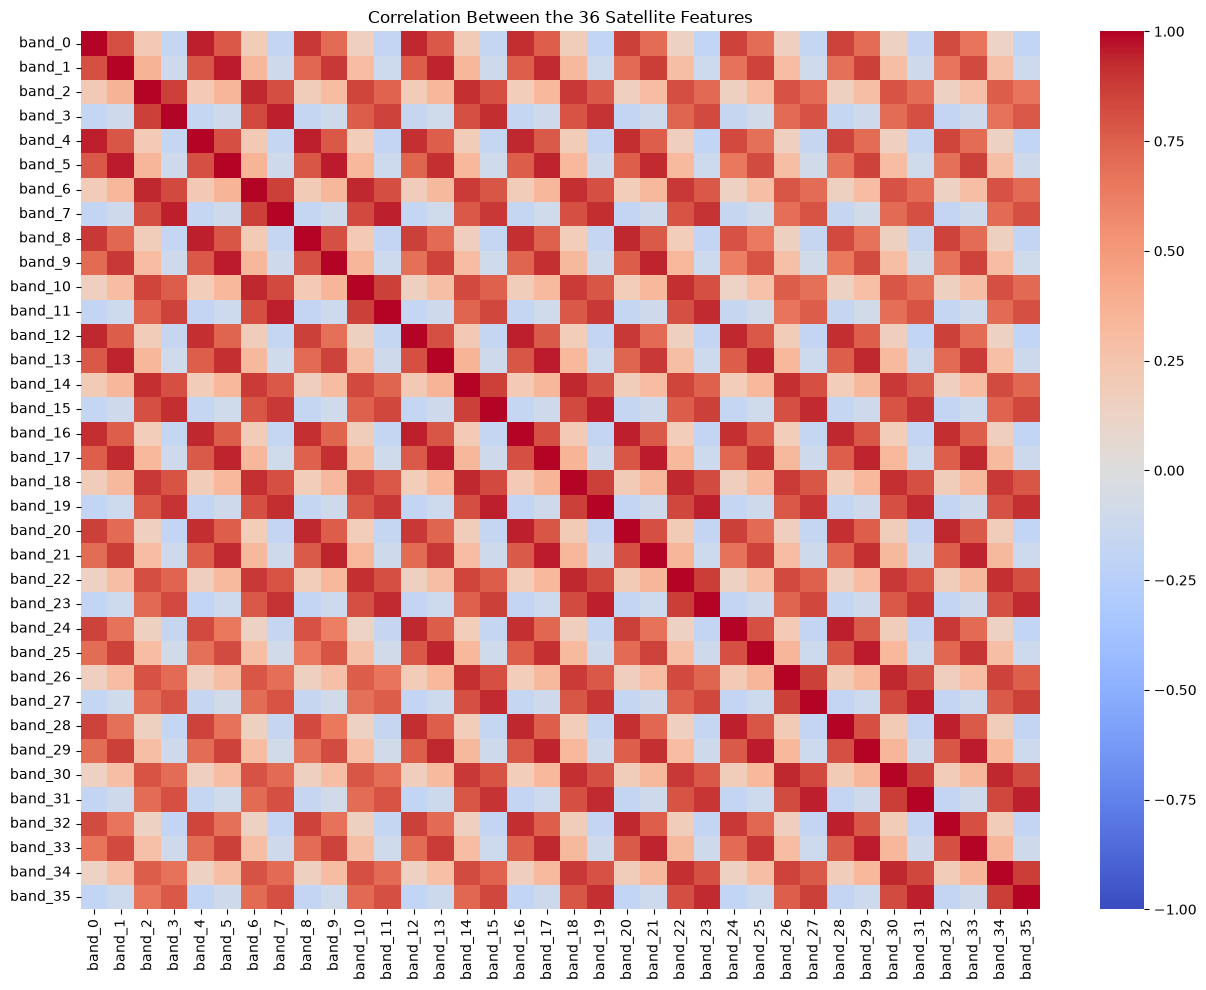

In [10]:
correlation = features.corr()
plt.figure(figsize=(13, 10))
sns.heatmap(correlation, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation Between the 36 Satellite Features")
plt.tight_layout()
plt.show()


### 5.4 Feature distributions by class

Boxplots for the first six bands provide a compact comparison of their values across the six target classes.

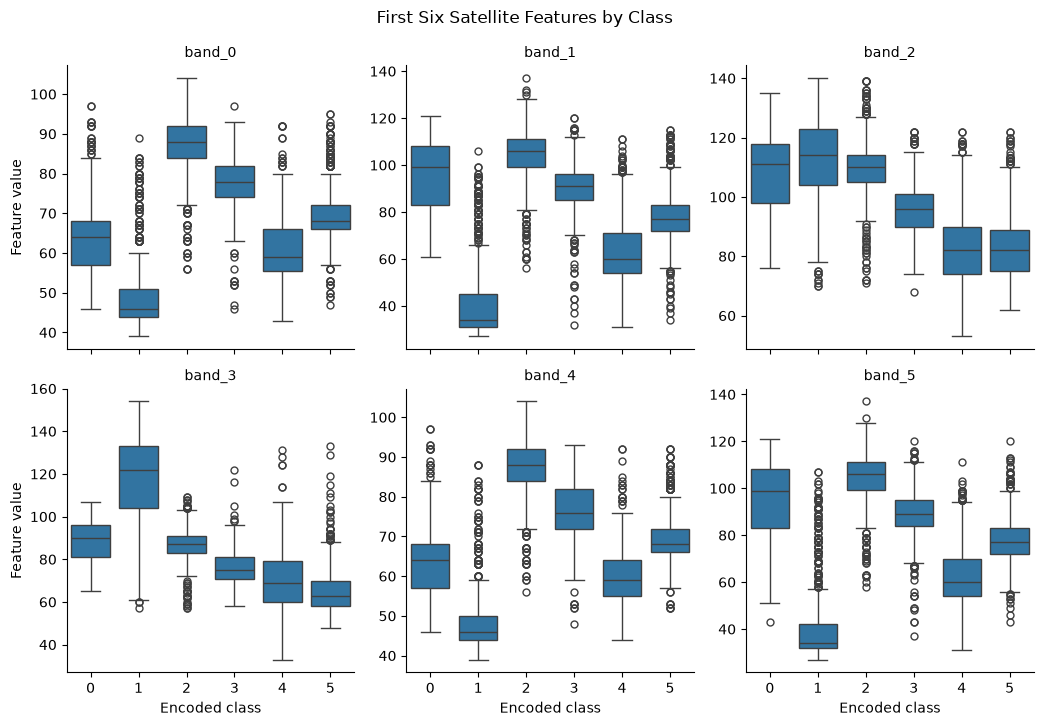

In [12]:
### 5.4 Feature distributions by class

feature_names = features.columns.tolist()

plot_df = df.melt(
    id_vars="label",
    value_vars=feature_names[:6],
    var_name="feature",
    value_name="value"
)

g = sns.catplot(
    data=plot_df,
    x="label",
    y="value",
    col="feature",
    kind="box",
    col_wrap=3,
    sharey=False,
    height=3.5
)

g.set_axis_labels("Encoded class", "Feature value")
g.set_titles("{col_name}")
g.fig.suptitle("First Six Satellite Features by Class", y=1.03)

plt.show()

## 6. Final preprocessing decisions

Based on the loader and the checks above:

1. Keep all 36 numeric spectral features.
2. Keep all six target classes; `label` is already integer-encoded.
3. Do not apply one-hot encoding to the features because they are already numeric measurements.
4. Do not apply scaling in this dataset-export step.
5. No missing values, infinite values, duplicate feature rows, or constant features were detected in the loaded data.
6. Export one combined dataset with 36 feature columns and one `label` column.

The exported CSV is the dataset after the original loader's preprocessing and this notebook's verification. It does **not** contain artificial label poisoning or train/test split assignments.

## 7. Export the preprocessed dataset

The CSV is written into the repository's `data/` folder so it can be reviewed and versioned with the notebook.

In [13]:
output_dir = PROJECT_ROOT / "Data"
output_dir.mkdir(parents=True, exist_ok=True)

output_path = output_dir / "satellite.csv"
df.to_csv(output_path, index=False)

print("Saved:", output_path)
print("Exported shape:", df.shape)
print("File size (KB):", round(output_path.stat().st_size / 1024, 2))

Saved: d:\Research Paper\Git\Soft-Reweighting-Samples\Data\satellite.csv
Exported shape: (6435, 37)
File size (KB): 751.26


## 8. Verify the exported CSV

In [14]:
exported = pd.read_csv(output_path)

assert exported.shape == df.shape
assert exported.columns.tolist() == df.columns.tolist()
assert exported.isna().sum().sum() == 0
assert exported["label"].isin(range(6)).all()

print("CSV verification passed.")
print("Shape:", exported.shape)
print("Columns:", exported.columns.tolist())
display(exported.head())


CSV verification passed.
Shape: (6435, 37)
Columns: ['band_0', 'band_1', 'band_2', 'band_3', 'band_4', 'band_5', 'band_6', 'band_7', 'band_8', 'band_9', 'band_10', 'band_11', 'band_12', 'band_13', 'band_14', 'band_15', 'band_16', 'band_17', 'band_18', 'band_19', 'band_20', 'band_21', 'band_22', 'band_23', 'band_24', 'band_25', 'band_26', 'band_27', 'band_28', 'band_29', 'band_30', 'band_31', 'band_32', 'band_33', 'band_34', 'band_35', 'label']


,band_0,band_1,band_2,band_3,band_4,band_5,band_6,band_7,band_8,band_9,...,band_27,band_28,band_29,band_30,band_31,band_32,band_33,band_34,band_35,label
0,92,115,120,94,84,102,106,79,84,102,...,104,88,121,128,100,84,107,113,87,2
1,84,102,106,79,84,102,102,83,80,102,...,100,84,107,113,87,84,99,104,79,2
2,84,102,102,83,80,102,102,79,84,94,...,87,84,99,104,79,84,99,104,79,2
3,80,102,102,79,84,94,102,79,80,94,...,79,84,99,104,79,84,103,104,79,2
4,84,94,102,79,80,94,98,76,80,102,...,79,84,103,104,79,79,107,109,87,2


## Summary

- The repository loader combines the official UCI training and test files, names the 36 spectral features, and integer-encodes the six-class target.
- The dataset contains 6,435 rows and 36 features.
- The audit checks missing/infinite values, duplicate feature rows, constant features, data types, value range, and class distribution.
- The final exported file is `data/satellite_preprocessed.csv`.